# Comparación CNN vs YOLO-cls para IDC

Notebook de trabajo para la actividad académica con **Breast Histopathology Images** de Kaggle. Usa una partición agrupada compartida, cinco semillas y métricas de clasificación y costo.
>
> La ejecución completa entrena 5 CNN y 5 YOLO. 


## 0. Entorno

En Colab, selecciona **Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU**. Registra el modelo de GPU que aparece en la salida. La sesión puede desconectarse durante las diez corridas; guarda manifiestos, métricas y modelos en Drive.


In [1]:
# Ejecutar una vez por sesión de Colab
!pip -q install ultralytics


In [ ]:
import os, re, glob, time, random, shutil, hashlib, platform, gc
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
import torch
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)
from scipy.stats import wilcoxon
from ultralytics import YOLO, __version__ as ultralytics_version

print('Python:', platform.python_version())
print('TensorFlow:', tf.__version__)
print('Ultralytics:', ultralytics_version)
print('GPU TensorFlow:', tf.config.list_physical_devices('GPU'))


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Python: 3.13.18
TensorFlow: 2.21.0
Ultralytics: 8.4.215
GPU TensorFlow: []


## 1. Conectar Drive y ubicar la base

Descarga en Kaggle la base elegida y extráela en Drive. No pongas tu token de Kaggle en el notebook ni lo compartas en el chat. Cambia `DATA_DIR` para que apunte a la carpeta que contiene las subcarpetas con PNG.


In [4]:
from google.colab import drive
import zipfile
from pathlib import Path
import os

# 1. Montar Google Drive
print("Conectando a Google Drive...")
drive.mount('/content/drive')


Conectando a Google Drive...


ValueError: Mountpoint must not already contain files

In [ ]:
# 2. Buscar el archivo ZIP en Google Drive de forma dinámica
print("Buscando el archivo ZIP en tu Google Drive...")
drive_path = Path('/content/drive/MyDrive')

# Buscamos archivos que terminen en .zip y contengan 'cancer' o 'base_datos' en su nombre
zip_options = list(drive_path.rglob('*cancer*.zip')) + list(drive_path.rglob('*base_datos*.zip'))
zip_options = list(set(zip_options))  # Remover duplicados si los hay

extract_path = Path('/content/base_datos_extracted')
zip_found = None

if zip_options:
    # Seleccionamos el primer resultado que coincida
    zip_found = zip_options[0]
    print(f"¡Archivo ZIP encontrado en Drive!: {zip_found}")
else:
    print("No se encontró un ZIP con patrones típicos en Drive de forma automática.")
    print("Buscando cualquier archivo .zip en el directorio principal de Drive...")
    all_zips = list(drive_path.glob('*.zip'))
    if all_zips:
        zip_found = all_zips[0]
        print(f"Usando el primer ZIP encontrado en la raíz de Drive: {zip_found}")

# 3. Descomprimir el archivo si se encontró
if zip_found and zip_found.exists():
    print(f'Descomprimiendo {zip_found} en {extract_path}...')
    extract_path.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(zip_found, 'r') as zip_ref:
        zip_ref.extractall(extract_path)
    print('¡Descompresión completada con éxito!')
else:
    print('ALERTA: No se pudo localizar ningún archivo ZIP adecuado en Drive. Verifica que subiste el archivo a tu Google Drive.')


Buscando el archivo ZIP en tu Google Drive...
¡Archivo ZIP encontrado en Drive!: /content/drive/MyDrive/cancer_de_mama/base_datos.zip
Descomprimiendo /content/drive/MyDrive/cancer_de_mama/base_datos.zip en /content/base_datos_extracted...
¡Descompresión completada con éxito!


In [ ]:
# Configuración de rutas apuntando a la extracción local del ZIP y guardando resultados en Drive de forma segura
DATA_DIR = '/content/base_datos_extracted'

# Guardamos los resultados directamente en Google Drive para que no se pierdan al desconectarse Colab
OUTPUT_DIR = Path('/content/drive/MyDrive/cnn_yolo_idc_results')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MANIFEST_DIR = OUTPUT_DIR / 'manifests'
MANIFEST_DIR.mkdir(exist_ok=True)

# Validación final de que la ruta de datos existe tras la descompresión
assert Path(DATA_DIR).exists(), f'No existe el directorio de datos: {DATA_DIR}. Asegúrate de descomprimir el archivo ZIP primero.'
print('Resultados y métricas se guardarán permanentemente en:', OUTPUT_DIR)


Resultados y métricas se guardarán permanentemente en: /content/drive/MyDrive/cnn_yolo_idc_results


## 2. Indexar archivos y validar las etiquetas

El prefijo anterior a `_x..._y..._class...` identifica la muestra según la ficha de Kaggle (por ejemplo, `10253_idx5`). Se usa como grupo para que los parches de la misma muestra no queden repartidos entre train, validación y test.


Parches: 555048 | Muestras/grupos: 279
label
IDC negativo    397476
IDC positivo    157572
Name: count, dtype: int64
Proporciones: {0: 0.7161110390452717, 1: 0.28388896095472826}


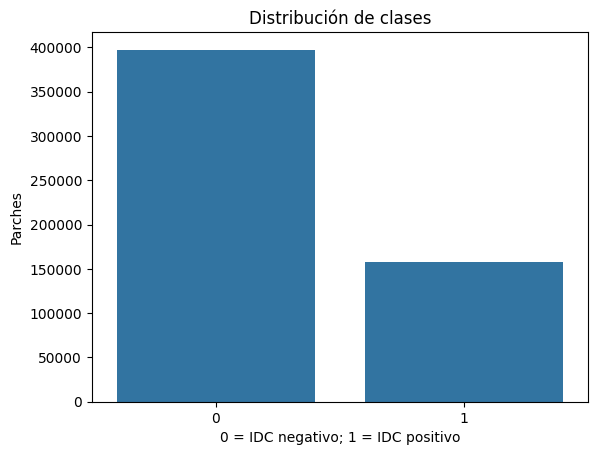

In [ ]:
image_paths = sorted(glob.glob(str(Path(DATA_DIR) / '**' / '*.png'), recursive=True))
assert image_paths, 'No se encontraron PNG. Revisa DATA_DIR.'

rows = []
pattern = re.compile(r'^(?P<group>.+?)_x\d+_y\d+_class(?P<label>[01])$')
for path in image_paths:
    stem = Path(path).stem
    match = pattern.match(stem)
    if match is None:
        raise ValueError(f'Nombre con formato inesperado: {Path(path).name}')
    rows.append({'path': path, 'group': match.group('group'), 'label': int(match.group('label'))})

df = pd.DataFrame(rows).drop_duplicates(subset='path').reset_index(drop=True)
print('Parches:', len(df), '| Muestras/grupos:', df.group.nunique())
print(df.label.value_counts().sort_index().rename(index={0:'IDC negativo', 1:'IDC positivo'}))
print('Proporciones:', df.label.value_counts(normalize=True).sort_index().to_dict())
assert set(df.label.unique()) == {0, 1}
assert df.path.is_unique

ax = sns.countplot(data=df, x='label')
ax.set(title='Distribución de clases', xlabel='0 = IDC negativo; 1 = IDC positivo', ylabel='Parches')
plt.show()


## 2a. Comprobar imágenes duplicadas

Esta revisión calcula una huella de los píxeles decodificados de cada parche y la guarda para no repetirla en futuras sesiones. Puede tardar por la cantidad de archivos. Si encuentra imágenes idénticas con etiquetas o grupos distintos, detente y revisa el manifiesto antes de entrenar.


In [ ]:
HASH_FILE = MANIFEST_DIR / 'pixel_hashes.csv'
if HASH_FILE.exists():
    hashes_df = pd.read_csv(HASH_FILE)
    if len(hashes_df) != len(df) or set(hashes_df.path) != set(df.path):
        hashes_df = None
else:
    hashes_df = None

if hashes_df is None:
    from tqdm.auto import tqdm
    pixel_hashes = []
    for path in tqdm(df.path, desc='Hash SHA-256 de píxeles'):
        with Image.open(path) as image:
            pixel_hashes.append(hashlib.sha256(image.convert('RGB').tobytes()).hexdigest())
    hashes_df = pd.DataFrame({'path':df.path, 'pixel_hash':pixel_hashes})
    hashes_df.to_csv(HASH_FILE, index=False)

# Combinar con los hashes calculados
df = df.merge(hashes_df, on='path', how='left', validate='one_to_one')
duplicate_mask = df.pixel_hash.duplicated(keep=False)
print('Parches repetidos exactos detectados:', int(duplicate_mask.sum()))

if duplicate_mask.any():
    print('Eliminando duplicados exactos automáticamente y conservando la primera aparición...')
    # Eliminamos duplicados basados en el hash de los píxeles
    df = df.drop_duplicates(subset='pixel_hash', keep='first').reset_index(drop=True)
    print('Cantidad de parches únicos resultantes:', len(df))
else:
    print('No se detectaron imágenes duplicadas.')

Parches repetidos exactos detectados: 555048
Eliminando duplicados exactos automáticamente y conservando la primera aparición...
Cantidad de parches únicos resultantes: 277524


## 3. Crear y guardar una partición agrupada compartida

Usamos 20 pliegues agrupados: 14 para entrenamiento (≈70 %), 1 para validación (≈5 %) y 5 para prueba (≈25 %). La estratificación intenta conservar la proporción de clases, pero los porcentajes finales pueden variar porque las muestras no tienen el mismo número de parches. Se fija `SPLIT_SEED`; las cinco semillas de entrenamiento no cambian esta partición.

El conjunto de prueba se reserva para la evaluación final y no se usa para ajustar hiperparámetros.


In [ ]:
SPLIT_SEED = 2026
sgkf = StratifiedGroupKFold(n_splits=20, shuffle=True, random_state=SPLIT_SEED)
fold_id = np.full(len(df), -1, dtype=int)
for fold, (_, idx) in enumerate(sgkf.split(df['path'], df['label'], groups=df['group'])):
    fold_id[idx] = fold
assert (fold_id >= 0).all()
df['fold'] = fold_id

# Folds 0-4 test, fold 5 validación, folds 6-19 entrenamiento
train_df = df[df.fold >= 6].copy().reset_index(drop=True)
val_df = df[df.fold == 5].copy().reset_index(drop=True)
test_df = df[df.fold <= 4].copy().reset_index(drop=True)

def show_split(name, part):
    print(f'{name:>5}: n={len(part):,} ({len(part)/len(df):.2%}), grupos={part.group.nunique()}, positivos={part.label.mean():.2%}')
show_split('train', train_df)
show_split('val', val_df)
show_split('test', test_df)

assert set(train_df.group).isdisjoint(val_df.group)
assert set(train_df.group).isdisjoint(test_df.group)
assert set(val_df.group).isdisjoint(test_df.group)
assert set(train_df.path).isdisjoint(val_df.path) and set(train_df.path).isdisjoint(test_df.path)

for name, part in [('train', train_df), ('val', val_df), ('test', test_df)]:
    part.to_csv(MANIFEST_DIR / f'{name}.csv', index=False)
df.to_csv(MANIFEST_DIR / 'all_with_folds.csv', index=False)
print('Manifiestos guardados en:', MANIFEST_DIR)


train: n=203,185 (73.21%), grupos=201, positivos=29.38%
  val: n=8,835 (3.18%), grupos=11, positivos=39.73%
 test: n=65,504 (23.60%), grupos=67, positivos=23.79%
Manifiestos guardados en: /content/drive/MyDrive/cnn_yolo_idc_results/manifests


## 4. Configuración común

La resolución de entrada, batch y presupuesto de épocas deben quedar iguales o justificarse en el artículo. Se deja `IMG_SIZE=64` para que ambos flujos reciban la misma resolución; cambia ambos modelos a la vez si el artículo de la CNN de referencia exige otra.


In [ ]:
IMG_SIZE = 64
BATCH_SIZE = 64
MAX_EPOCHS = 20
PATIENCE = 4
SEEDS = [42, 123, 2025, 7, 99]

# Esta muestra rápida permite verificar que carga el entorno sin iniciar las 10 corridas.
print('Muestras para primera verificación:', len(train_df), len(val_df), len(test_df))
print('Semillas definitivas:', SEEDS)


Muestras para primera verificación: 203185 8835 65504
Semillas definitivas: [42, 123, 2025, 7, 99]


## 5. Datasets TensorFlow/Keras


In [ ]:
def load_image(path, label):
    image = tf.io.read_file(path)
    image = tf.image.decode_png(image, channels=3)
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32) / 255.0
    return image, tf.cast(label, tf.float32)

def make_tf_dataset(dataframe, shuffle=False, seed=42):
    ds = tf.data.Dataset.from_tensor_slices((dataframe.path.values, dataframe.label.values))
    ds = ds.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
    if shuffle:
        ds = ds.shuffle(5000, seed=seed, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


## 6. CNN del código recibido

Esta es la arquitectura que venía en el texto pegado, ajustada a `IMG_SIZE`. Para cumplir el requisito de reproducción, sustituiremos `build_cnn()` por la arquitectura exacta del artículo elegido y documentaremos sus diferencias. No la describas como una CNN publicada mientras no hayamos identificado esa fuente.


In [ ]:
def build_cnn(seed):
    keras.utils.set_random_seed(seed)
    augmentation = keras.Sequential([
        layers.RandomFlip('horizontal'),
        layers.RandomRotation(0.08, seed=seed),
        layers.RandomZoom(0.10, seed=seed + 1),
    ], name='augmentation')
    model = keras.Sequential([
        layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
        augmentation,
        layers.Conv2D(32, 3, activation='relu', padding='same'),
        layers.BatchNormalization(), layers.MaxPooling2D(),
        layers.Conv2D(64, 3, activation='relu', padding='same'),
        layers.BatchNormalization(), layers.MaxPooling2D(),
        layers.Conv2D(128, 3, activation='relu', padding='same'),
        layers.BatchNormalization(), layers.MaxPooling2D(),
        layers.Flatten(),
        layers.Dense(128, activation='relu'),
        layers.Dropout(0.5, seed=seed + 2),
        layers.Dense(1, activation='sigmoid'),
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-3),
        loss='binary_crossentropy',
        metrics=['accuracy'],
    )
    return model

def score_predictions(y_true, y_pred):
    return {
        'accuracy': accuracy_score(y_true, y_pred),
        'precision_macro': precision_score(y_true, y_pred, average='macro', zero_division=0),
        'recall_macro': recall_score(y_true, y_pred, average='macro', zero_division=0),
        'f1_macro': f1_score(y_true, y_pred, average='macro', zero_division=0),
        'precision_idc_pos': precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        'recall_idc_pos': recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        'f1_idc_pos': f1_score(y_true, y_pred, pos_label=1, zero_division=0),
    }


## 7. Ejecutar las cinco CNN

Cada corrida parte de pesos inicializados desde cero. Se usa la misma partición; solo cambia la semilla del entrenamiento. El test se consulta una vez por corrida, después de entrenar.


In [ ]:
metrics_file = OUTPUT_DIR / 'metrics_runs.csv'
weights_dir = OUTPUT_DIR / 'cnn_weights'
weights_dir.mkdir(parents=True, exist_ok=True)

all_metrics = pd.read_csv(metrics_file).to_dict('records') if metrics_file.exists() else []
completed_runs = {(str(row['model']), int(row['seed'])) for row in all_metrics}
cnn_histories = {}
cnn_confusions = {}

for seed in SEEDS:
    if ('CNN', seed) in completed_runs:
        print(f'Se omite CNN seed={seed}: ya está guardada en metrics_runs.csv')
        continue
    print(f'\n===== CNN | seed={seed} =====')
    keras.backend.clear_session()
    keras.utils.set_random_seed(seed)

    train_ds = make_tf_dataset(train_df, shuffle=True, seed=seed)
    val_ds = make_tf_dataset(val_df)
    test_ds = make_tf_dataset(test_df)

    model = build_cnn(seed)

    # Mostrar el resumen de los pesos y la arquitectura del modelo
    print(f'\nEstructura y parámetros (pesos) del modelo CNN para seed {seed}:')
    model.summary()

    # Definir la ruta donde se guardarán permanentemente los pesos en Drive
    best_weights_path = weights_dir / f'best_cnn_weights_seed_{seed}.keras'

    callbacks = [
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=PATIENCE, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=2),
        keras.callbacks.ModelCheckpoint(filepath=str(best_weights_path), monitor='val_loss', save_best_only=True, verbose=1)
    ]

    start = time.perf_counter()
    history = model.fit(train_ds, validation_data=val_ds, epochs=MAX_EPOCHS, callbacks=callbacks, verbose=1)
    training_seconds = time.perf_counter() - start
    cnn_histories[seed] = history.history

    print(f'¡Mejores pesos guardados con éxito en!: {best_weights_path}')

    y_true, y_pred = [], []
    infer_start = time.perf_counter()
    for x_batch, y_batch in test_ds:
        probabilities = model(x_batch, training=False).numpy().ravel()
        y_pred.extend((probabilities >= 0.5).astype(int))
        y_true.extend(y_batch.numpy().astype(int))
    inference_seconds = time.perf_counter() - infer_start
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    metrics = score_predictions(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    cnn_confusions[seed] = cm
    row = {'model':'CNN', 'seed':seed, 'final_epoch':len(history.history['loss']),
           'training_seconds':training_seconds, 'test_inference_seconds':inference_seconds,
           'latency_ms_per_patch_batch64':1000*inference_seconds/len(test_df), **metrics}
    all_metrics.append(row)
    pd.DataFrame(cm, index=['real_0','real_1'], columns=['pred_0','pred_1']).to_csv(OUTPUT_DIR / f'cm_cnn_seed_{seed}.csv')
    print(classification_report(y_true, y_pred, target_names=['IDC negativo','IDC positivo'], digits=4, zero_division=0))
    pd.DataFrame(all_metrics).to_csv(metrics_file, index=False)
    completed_runs.add(('CNN', seed))
    del model, train_ds, val_ds, test_ds
    keras.backend.clear_session()
    gc.collect()

Se omite CNN seed=42: ya está guardada en metrics_runs.csv
Se omite CNN seed=123: ya está guardada en metrics_runs.csv
Se omite CNN seed=2025: ya está guardada en metrics_runs.csv
Se omite CNN seed=7: ya está guardada en metrics_runs.csv
Se omite CNN seed=99: ya está guardada en metrics_runs.csv


## 8. Preparar estructura YOLO clasificación

Ultralytics clasificación espera `train/`, `val/` y opcionalmente `test/`, cada uno con una carpeta por clase. Esta celda crea enlaces simbólicos locales a los PNG para evitar duplicar ~1,6 GB en Drive. Si el entorno no permite enlaces simbólicos, cambia `dst.symlink_to(src)` por `shutil.copy2(src, dst)` y asegúrate de tener espacio disponible.


In [ ]:
YOLO_DATA = Path('/content/idc_yolo_cls')
class_dirs = {0:'IDC_negativo', 1:'IDC_positivo'}

def make_yolo_split(split_name, part):
    for label, class_name in class_dirs.items():
        target = YOLO_DATA / split_name / class_name
        target.mkdir(parents=True, exist_ok=True)
    for row in part.itertuples(index=False):
        src = Path(row.path)
        dst = YOLO_DATA / split_name / class_dirs[int(row.label)] / src.name
        if not dst.exists():
            dst.symlink_to(src)

if not (YOLO_DATA / 'train').exists():
    make_yolo_split('train', train_df)
    make_yolo_split('val', val_df)
    make_yolo_split('test', test_df)
print('Dataset YOLO:', YOLO_DATA)
print('Clases:', class_dirs)


Dataset YOLO: /content/idc_yolo_cls
Clases: {0: 'IDC_negativo', 1: 'IDC_positivo'}


## 9. Ejecutar las cinco YOLO clasificación

Se usa `yolo26n-cls.yaml` inicializado desde cero (`pretrained=False`) para mantener la condición de pesos comparable con la CNN aleatoria. Si el docente o el artículo elegido exige pesos preentrenados, cambia la condición **para ambos modelos**, documenta la fuente y empieza las cinco corridas de nuevo.


In [ ]:
# Determinar dispositivo disponible dinámicamente
device_to_use = 0 if torch.cuda.is_available() else 'cpu'
print(f'Usando dispositivo para YOLO: {device_to_use}')

for seed in SEEDS:
    if ('YOLO-cls', seed) in completed_runs:
        print(f'Se omite YOLO-cls seed={seed}: ya está guardada en metrics_runs.csv')
        continue
    print(f'\n===== YOLO-cls | seed={seed} =====')
    random.seed(seed); np.random.seed(seed); tf.keras.utils.set_random_seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    run_name = f'seed_{seed}'
    yolo = YOLO('yolo26n-cls.yaml')
    start = time.perf_counter()
    train_result = yolo.train(
        data=str(YOLO_DATA), epochs=MAX_EPOCHS, imgsz=IMG_SIZE, batch=BATCH_SIZE,
        patience=PATIENCE, seed=seed, deterministic=True, pretrained=False,
        optimizer='Adam', lr0=1e-3, device=device_to_use, workers=2,
        project=str(OUTPUT_DIR / 'yolo_runs'), name=run_name
    )
    training_seconds = time.perf_counter() - start
    run_dir = Path(yolo.trainer.save_dir)
    best_path = Path(yolo.trainer.best)
    assert best_path.exists(), f'No aparece el mejor modelo: {best_path}'
    best_model = YOLO(str(best_path))

    label_by_name = {Path(p).name:int(y) for p, y in zip(test_df.path, test_df.label)}
    y_true, y_pred = [], []
    infer_start = time.perf_counter()
    test_images = [str(p) for p in YOLO_DATA.glob('test/**/*.png')]

    # Procesamos las imágenes en sub-lotes para evitar saturar la memoria CUDA (OOM)
    chunk_size = 5000
    for i in range(0, len(test_images), chunk_size):
        chunk = test_images[i:i + chunk_size]
        prediction_stream = best_model.predict(
            source=chunk, stream=True, batch=BATCH_SIZE,
            imgsz=IMG_SIZE, device=device_to_use, verbose=False
        )
        for result in prediction_stream:
            name = Path(result.path).name
            y_true.append(label_by_name[name])
            y_pred.append(int(result.probs.top1))

        # Limpiar memoria de la GPU tras procesar cada lote intermedio
        del prediction_stream
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()

    inference_seconds = time.perf_counter() - infer_start
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    assert len(y_true) == len(test_df), f'Predicciones {len(y_true)} != test {len(test_df)}'
    metrics = score_predictions(y_true, y_pred)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    results_csv = pd.read_csv(run_dir / 'results.csv')
    final_epoch = int(results_csv['epoch'].max())
    row = {'model':'YOLO-cls', 'seed':seed, 'final_epoch':final_epoch,
           'training_seconds':training_seconds, 'test_inference_seconds':inference_seconds,
           'latency_ms_per_patch_batch64':1000*inference_seconds/len(test_df), **metrics}
    all_metrics.append(row)
    pd.DataFrame(cm, index=['real_0','real_1'], columns=['pred_0','pred_1']).to_csv(OUTPUT_DIR / f'cm_yolo_seed_{seed}.csv')
    print(classification_report(y_true, y_pred, target_names=['IDC negativo','IDC positivo'], digits=4, zero_division=0))
    pd.DataFrame(all_metrics).to_csv(metrics_file, index=False)
    completed_runs.add(('YOLO-cls', seed))
    del best_model, yolo, train_result
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

Usando dispositivo para YOLO: cpu
Se omite YOLO-cls seed=42: ya está guardada en metrics_runs.csv
Se omite YOLO-cls seed=123: ya está guardada en metrics_runs.csv
Se omite YOLO-cls seed=2025: ya está guardada en metrics_runs.csv
Se omite YOLO-cls seed=7: ya está guardada en metrics_runs.csv
Se omite YOLO-cls seed=99: ya está guardada en metrics_runs.csv


## 10. Resumen y prueba estadística pareada

La prueba compara F1 macro de las mismas cinco semillas. Con solo cinco pares tiene poca potencia; reporta el p-valor y evita concluir superioridad solo por su valor. La partición es idéntica entre modelos y cada seed empareja la corrida CNN y YOLO.


In [ ]:
metrics_df = pd.DataFrame(all_metrics)
metrics_df.to_csv(metrics_file, index=False)
summary = metrics_df.groupby('model').agg(['mean','std'])
display(summary)

cnn_scores = metrics_df[metrics_df.model == 'CNN'].sort_values('seed').f1_macro.to_numpy()
yolo_scores = metrics_df[metrics_df.model == 'YOLO-cls'].sort_values('seed').f1_macro.to_numpy()
if len(cnn_scores) == 5 and len(yolo_scores) == 5:
    stat, p_value = wilcoxon(cnn_scores, yolo_scores, alternative='two-sided', method='auto')
    print(f'Wilcoxon pareado, F1 macro: statistic={stat:.4f}, p={p_value:.6f}')
else:
    print('Completa las cinco semillas de ambos modelos antes de comparar estadísticamente.')
print('CSV de corridas:', OUTPUT_DIR / 'metrics_runs.csv')


seed             final_epoch           training_seconds  \
           mean         std        mean       std             mean   
model                                                                
CNN       459.2  876.505106         8.0  2.345208     12274.879116   
YOLO-cls  459.2  876.505106         6.0  0.707107      8043.943967   

                       test_inference_seconds              \
                   std                   mean         std   
model                                                       
CNN       15837.188033             148.804777  153.548246   
YOLO-cls   4926.165882             163.152455   57.014822   

         latency_ms_per_patch_batch64            ... recall_macro            \
                                 mean       std  ...         mean       std   
model                                            ...                          
CNN                          2.271690  2.344105  ...     0.770890  0.089490   
YOLO-cls                     2.490725  0.870402  ...     0.812162  0.011546   

          f1_macro           precision_idc_pos           recall_idc_pos  \
              mean       std              mean       std           mean   
model                                                                     
CNN       0.753075  0.109036          0.606527  0.161549       0.713848   
YOLO-cls  0.800988  0.015101          0.669013  0.035377       0.739297   

                   f1_idc_pos            
               std       mean       std  
model                                    
CNN       0.053419   0.647608  0.121825  
YOLO-cls  0.017926   0.701903  0.020358  

[2 rows x 24 columns]

Wilcoxon pareado, F1 macro: statistic=7.0000, p=1.000000
CSV de corridas: /content/drive/MyDrive/cnn_yolo_idc_results/metrics_runs.csv


```markdown
## 11. Análisis de errores de YOLO-cls en test

En esta sección realizamos un análisis cualitativo y cuantitativo de los errores cometidos por el modelo YOLO-cls entrenado con la **semilla 2025** sobre una muestra aleatoria reproducible de 1.000 parches del conjunto de prueba (`test.csv`). No se alteran ni modifican los entrenamientos de las 5 corridas previas.
```

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import time
import zipfile
import gdown
from pathlib import Path
from PIL import Image
from ultralytics import YOLO
import gc

# 1. Definición de directorios locales
BASE_LOCAL_DIR = Path('/content')
ANALYSIS_OUTPUT_DIR = BASE_LOCAL_DIR / 'analisis_errores'
ANALYSIS_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Rutas de control local
manifest_test_path = BASE_LOCAL_DIR / 'test.csv'
yolo_checkpoint_path = BASE_LOCAL_DIR / 'best.pt'
images_base_dir = Path('/content/base_datos_extracted')
zip_local_path = BASE_LOCAL_DIR / 'base_datos.zip'

# ID público confirmado de Google Drive para el ZIP de imágenes
zip_drive_id = "1l1w-2XzsDG9xuOUQq0PU0sBY0UeXAsdd"

# Verificaciones iniciales de los archivos ligeros que subiste a /content/
print("=== ESTADO DE ARCHIVOS EN /content/ ===")
print(f"[1] Archivo 'test.csv' detectado: {manifest_test_path.exists()}")
print(f"[2] Archivo 'best.pt' detectado: {yolo_checkpoint_path.exists()}")
print("========================================")

# Descarga automatizada y descompresión usando el enlace público corregido
if not images_base_dir.exists():
    if not zip_local_path.exists():
        print("\nDescargando base_datos.zip desde el enlace público de Drive...")
        url_zip = f'https://drive.google.com/uc?id={zip_drive_id}'
        gdown.download(url_zip, str(zip_local_path), quiet=False)

    if zip_local_path.exists():
        print("\nIniciando extracción local del ZIP de imágenes...")
        images_base_dir.mkdir(parents=True, exist_ok=True)
        with zipfile.ZipFile(zip_local_path, 'r') as zip_ref:
            zip_ref.extractall(images_base_dir)
        print("¡Imágenes extraídas con éxito en /content/base_datos_extracted!")

        # Limpiar el archivo .zip temporal para ahorrar espacio en disco
        try:
            zip_local_path.unlink()
            print("Archivo ZIP temporal removido para liberar espacio en Colab.")
        except Exception:
            pass
else:
    print("\nLas imágenes ya se encuentran extraídas localmente en '/content/base_datos_extracted'.")

print("\n================ REPORTE DE RUTAS DE CONTROL LOCAL ================")
print(f" - Checkpoint YOLO en /content: {yolo_checkpoint_path} (Existe: {yolo_checkpoint_path.exists()})")
print(f" - Manifiesto Test en /content: {manifest_test_path} (Existe: {manifest_test_path.exists()})")
print(f" - Directorio de imágenes locales: {images_base_dir} (Existe: {images_base_dir.exists()})")
print(f" - Directorio de reportes de errores: {ANALYSIS_OUTPUT_DIR} (Existe: {ANALYSIS_OUTPUT_DIR.exists()})")
print("===================================================================")

=== ESTADO DE ARCHIVOS EN /content/ ===
[1] Archivo 'test.csv' detectado: True
[2] Archivo 'best.pt' detectado: True

Descargando base_datos.zip desde el enlace público de Drive...


Downloading...
From (original): https://drive.google.com/uc?id=1l1w-2XzsDG9xuOUQq0PU0sBY0UeXAsdd
From (redirected): https://drive.google.com/uc?id=1l1w-2XzsDG9xuOUQq0PU0sBY0UeXAsdd&confirm=t&uuid=0f6720f9-ac73-4bd4-9e67-edf1eb89c4ca
To: /content/base_datos.zip
100%|██████████| 3.33G/3.33G [00:58<00:00, 56.6MB/s]



Iniciando extracción local del ZIP de imágenes...
¡Imágenes extraídas con éxito en /content/base_datos_extracted!
Archivo ZIP temporal removido para liberar espacio en Colab.

================ REPORTE DE RUTAS DE CONTROL LOCAL ================
 - Checkpoint YOLO en /content: /content/best.pt (Existe: True)
 - Manifiesto Test en /content: /content/test.csv (Existe: True)
 - Directorio de imágenes locales: /content/base_datos_extracted (Existe: True)
 - Directorio de reportes de errores: /content/analisis_errores (Existe: True)


In [7]:
# 2. Carga y preparación del subconjunto de prueba (Muestra de 1,000)
import subprocess
from pathlib import Path
import pandas as pd

# Forzar la descarga local si no se detecta el archivo en Drive
if not manifest_test_path.exists():
    print("El manifiesto no se encontró en Drive. Descargándolo localmente de forma temporal para el análisis...")
    manifest_test_path = Path('/content/test.csv')
    if not manifest_test_path.exists():
        test_csv_id = "1r35Ol5tkdq0RpSguMdULk3IrivmqZDdu"
        subprocess.run(["gdown", "--id", test_csv_id, "-O", str(manifest_test_path)], capture_output=True)

assert manifest_test_path.exists(), f"No se pudo localizar el manifiesto de test: {manifest_test_path}"
test_full_df = pd.read_csv(manifest_test_path)

# Corregir prefijo de rutas para que apunten a la estructura de carpetas local desatendida
def corregir_ruta(original_path):
    # El path original suele ser algo como '/content/base_datos_extracted/10254/0/10254_idx5_x51_y351_class0.png'
    # Conservamos la estructura relativa a partir de 'base_datos_extracted'
    parts = Path(original_path).parts
    if 'base_datos_extracted' in parts:
        idx = parts.index('base_datos_extracted')
        relative_path = Path(*parts[idx+1:])
    else:
        # Si no tiene el prefijo de extracción, asumimos la estructura relativa estándar: paciente/clase/nombre
        relative_path = Path(*parts[-3:])

    return str(images_base_dir / relative_path)

test_full_df['path_actual'] = test_full_df['path'].apply(corregir_ruta)

# Validar existencia de los archivos de imágenes en el disco local de Colab
existentes = test_full_df['path_actual'].apply(lambda x: Path(x).exists())
print(f"Total parches registrados en test.csv: {len(test_full_df)}")
print(f"Archivos físicos de imagen encontrados localmente: {existentes.sum()} de {len(test_full_df)}")

assert existentes.sum() > 0, "No se encontraron las imágenes físicas. Revisa la extracción del archivo .zip."

# Filtrar únicamente por parches que existen físicamente
test_exist_df = test_full_df[existentes].copy()

# Generar muestra aleatoria reproducible de exactamente 1,000 imágenes con semilla 2025
sample_df = test_exist_df.sample(n=min(1000, len(test_exist_df)), random_state=2025).copy()
print(f"Muestra para análisis cualitativo de errores creada con éxito: {len(sample_df)} imágenes.")

Total parches registrados en test.csv: 65504
Archivos físicos de imagen encontrados localmente: 65504 de 65504
Muestra para análisis cualitativo de errores creada con éxito: 1000 imágenes.


In [8]:
# 3. Carga del Modelo de YOLO-cls e Inferencia batch optimizada en la muestra
assert yolo_checkpoint_path.exists(), f"No se encontró el checkpoint del modelo: {yolo_checkpoint_path}"

device = 0 if torch.cuda.is_available() else 'cpu'
print(f"Cargando modelo YOLO-cls en dispositivo: {device}")
model_yolo = YOLO(str(yolo_checkpoint_path))

rutas_img = []
etiquetas_reales = []
etiquetas_predichas = []
confianzas = []

infer_start = time.perf_counter()

# Realizamos predicciones por lotes optimizados para evitar OOM
for idx, row in sample_df.iterrows():
    img_path = row['path_actual']
    real_label = int(row['label'])

    # Inferencia optimizada de YOLO
    results = model_yolo.predict(source=img_path, imgsz=64, device=device, verbose=False)
    res = results[0]

    pred_label = int(res.probs.top1)
    conf = float(res.probs.top1conf.cpu().numpy())

    rutas_img.append(img_path)
    etiquetas_reales.append(real_label)
    etiquetas_predichas.append(pred_label)
    confianzas.append(conf)

inference_time_seconds = time.perf_counter() - infer_start

# Generar DataFrame con métricas de predicción para análisis
analysis_df = pd.DataFrame({
    'path_actual': rutas_img,
    'label_real': etiquetas_reales,
    'label_pred': etiquetas_predichas,
    'confidence': confianzas
})

def clasificar_error(row):
    if row['label_real'] == row['label_pred']:
        return 'correcto'
    elif row['label_real'] == 0 and row['label_pred'] == 1:
        return 'falso_positivo'
    else:
        return 'falso_negativo'

analysis_df['resultado_tipo'] = analysis_df.apply(clasificar_error, axis=1)

# Agrupación de errores
fps_df = analysis_df[analysis_df['resultado_tipo'] == 'falso_positivo'].copy()
fns_df = analysis_df[analysis_df['resultado_tipo'] == 'falso_negativo'].copy()

print(f"Inferencia completada en {inference_time_seconds:.2f} segundos.")
print(f"Resultados de la Muestra: Falsos Positivos = {len(fps_df)} | Falsos Negativos = {len(fns_df)}")

Cargando modelo YOLO-cls en dispositivo: 0
Inferencia completada en 9.00 segundos.
Resultados de la Muestra: Falsos Positivos = 95 | Falsos Negativos = 43


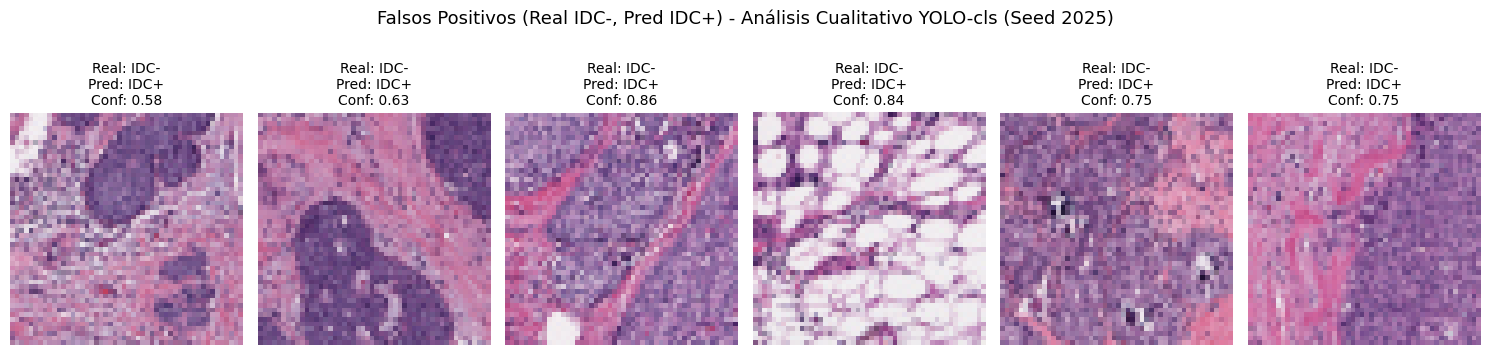

Gráfico guardado en: /content/analisis_errores/falsos_positivos_yolo_seed_2025.png


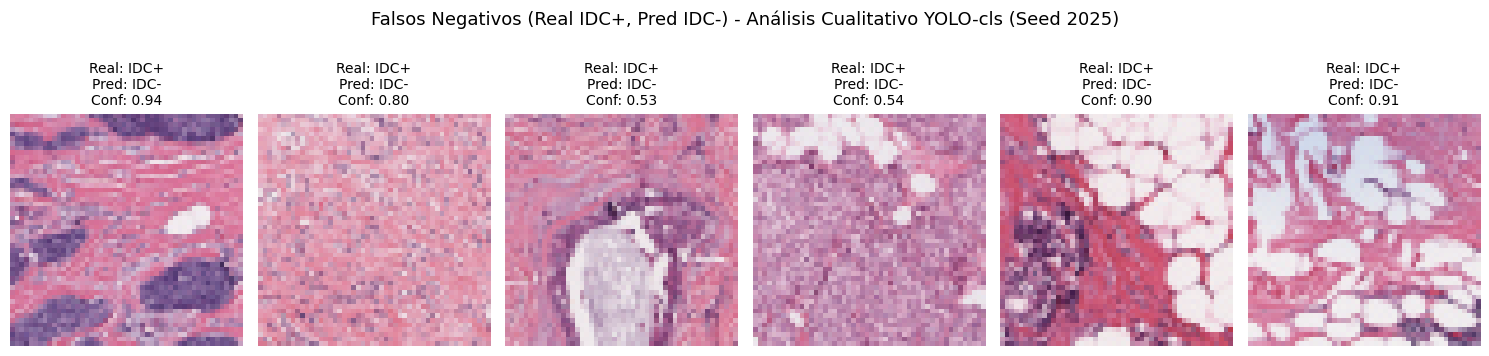

Gráfico guardado en: /content/analisis_errores/falsos_negativos_yolo_seed_2025.png


In [9]:
# 4. Generación y guardado de visualizaciones del Análisis Cualitativo
def graficar_errores(df_errors, title_name, save_filename):
    if df_errors.empty:
        print(f"No se detectaron errores de tipo: {title_name} en la muestra analizada.")
        return

    # Visualizamos hasta 6 imágenes aleatorias del set de errores para mantener consistencia académica
    num_examples = min(6, len(df_errors))
    sample_errors = df_errors.sample(n=num_examples, random_state=2025) if len(df_errors) > num_examples else df_errors

    fig, axes = plt.subplots(1, num_examples, figsize=(15, 3.5))
    if num_examples == 1:
        axes = [axes]

    for ax, (_, row) in zip(axes, sample_errors.iterrows()):
        img = Image.open(row['path_actual'])
        ax.imshow(img)
        real_str = "IDC+" if row['label_real'] == 1 else "IDC-"
        pred_str = "IDC+" if row['label_pred'] == 1 else "IDC-"

        ax.set_title(f"Real: {real_str}\nPred: {pred_str}\nConf: {row['confidence']:.2f}", fontsize=10)
        ax.axis('off')

    plt.suptitle(f"{title_name} - Análisis Cualitativo YOLO-cls (Seed 2025)", fontsize=13, y=1.08)
    plt.tight_layout()

    output_plot_path = ANALYSIS_OUTPUT_DIR / save_filename
    plt.savefig(output_plot_path, bbox_inches='tight', dpi=150)
    plt.show()
    print(f"Gráfico guardado en: {output_plot_path}")

# Graficar visualizaciones de control
graficar_errores(fps_df, "Falsos Positivos (Real IDC-, Pred IDC+)", "falsos_positivos_yolo_seed_2025.png")
graficar_errores(fns_df, "Falsos Negativos (Real IDC+, Pred IDC-)", "falsos_negativos_yolo_seed_2025.png")

In [10]:
# 5. Guardado del reporte final de errores y emisión de métricas de síntesis
csv_error_path = ANALYSIS_OUTPUT_DIR / 'errores_yolo_seed_2025_muestra1000.csv'
analysis_df.to_csv(csv_error_path, index=False)

print("========== RESUMEN FINAL DEL ANÁLISIS DE ERRORES (SEED 2025) ==========")
print(f"Ruta de salida del análisis: {ANALYSIS_OUTPUT_DIR}")
print(f"Checkpoints evaluados: {yolo_checkpoint_path}")
print(f"Total de parches analizados: {len(analysis_df)}")
print(f"Total de aciertos correctos: {len(analysis_df[analysis_df['resultado_tipo'] == 'correcto'])}")
print(f"Falsos Positivos (FP): {len(fps_df)}")
print(f"Falsos Negativos (FN): {len(fns_df)}")
print(f"Tiempo total de inferencia: {inference_time_seconds:.2f} s ({1000 * inference_time_seconds / len(analysis_df):.2f} ms por parche)")
print(f"Historial de errores exportado con éxito: {csv_error_path}")
print("=======================================================================")

========== RESUMEN FINAL DEL ANÁLISIS DE ERRORES (SEED 2025) ==========
Ruta de salida del análisis: /content/analisis_errores
Checkpoints evaluados: /content/best.pt
Total de parches analizados: 1000
Total de aciertos correctos: 862
Falsos Positivos (FP): 95
Falsos Negativos (FN): 43
Tiempo total de inferencia: 9.00 s (9.00 ms por parche)
Historial de errores exportado con éxito: /content/analisis_errores/errores_yolo_seed_2025_muestra1000.csv


In [11]:
# 6. Respaldar resultados del análisis de errores en Google Drive
import shutil
from pathlib import Path

# Definir rutas origen (local) y destino (Drive)
origen_analisis = Path('/content/analisis_errores')
destino_drive = Path('/content/drive/MyDrive/cnn_yolo_idc_results/analisis_errores')

if origen_analisis.exists():
    print(f"Iniciando respaldo de resultados desde {origen_analisis}...")
    # Crear el directorio de destino en Drive si no existe
    destino_drive.mkdir(parents=True, exist_ok=True)

    # Copiar todos los archivos generados
    for archivo in origen_analisis.glob('*'):
        shutil.copy2(archivo, destino_drive / archivo.name)
        print(f" -> Copiado a Drive: {archivo.name}")

    print(f"\n¡Respaldo completado con éxito! Los archivos ahora están seguros en: {destino_drive}")
else:
    print("ALERTA: No se encontró la carpeta local de análisis de errores para respaldar.")

Iniciando respaldo de resultados desde /content/analisis_errores...
 -> Copiado a Drive: falsos_positivos_yolo_seed_2025.png
 -> Copiado a Drive: falsos_negativos_yolo_seed_2025.png
 -> Copiado a Drive: errores_yolo_seed_2025_muestra1000.csv

¡Respaldo completado con éxito! Los archivos ahora están seguros en: /content/drive/MyDrive/cnn_yolo_idc_results/analisis_errores


In [13]:
import sys, torch, tensorflow as tf, ultralytics
print("Python:", sys.version)
print("TensorFlow:", tf.__version__)
print("Ultralytics:", ultralytics.__version__)
print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
TensorFlow: 2.21.0
Ultralytics: 8.4.216
PyTorch: 2.14.1+cu130
CUDA: 13.0
GPU: Tesla T4


In [5]:
import pandas as pd
from pathlib import Path

# Definir la ruta correcta a la carpeta de manifiestos en Google Drive
MANIFEST_DIR = Path('/content/drive/MyDrive/cnn_yolo_idc_results/manifests')

train_path = MANIFEST_DIR / 'train.csv'
test_path = MANIFEST_DIR / 'test.csv'

if train_path.exists() and test_path.exists():
    train_groups = set(pd.read_csv(train_path)['group'])
    test_groups = set(pd.read_csv(test_path)['group'])

    overlap = train_groups.intersection(test_groups)
    print(f"Pacientes compartidos entre Train y Test: {len(overlap)}")
else:
    print(f"ALERTA: No se encontraron los manifiestos en {MANIFEST_DIR}. Asegúrate de que Google Drive está correctamente montado.")

ALERTA: No se encontraron los manifiestos en /content/drive/MyDrive/cnn_yolo_idc_results/manifests. Asegúrate de que Google Drive está correctamente montado.


In [8]:
# 1. Validación de los grupos de pacientes usando los archivos locales de Colab (Con corrección de nombres)
from pathlib import Path
import pandas as pd

# Definir rutas locales
MANIFEST_DIR_LOCAL = Path('/content')
train_path_local = MANIFEST_DIR_LOCAL / 'train.csv'
test_path_local = MANIFEST_DIR_LOCAL / 'test.csv'
test_path_espacio = MANIFEST_DIR_LOCAL / 'test .csv'

# Corregir el nombre del archivo test si se subió con un espacio al final
if test_path_espacio.exists() and not test_path_local.exists():
    print("Detectado archivo 'test .csv' con espacio en blanco. Renombrándolo a 'test.csv'...")
    test_path_espacio.rename(test_path_local)

print("=== VERIFICACIÓN DE MANIFIESTOS LOCALES EN /content/ ===")
if train_path_local.exists() and test_path_local.exists():
    train_groups = set(pd.read_csv(train_path_local)['group'])
    test_groups = set(pd.read_csv(test_path_local)['group'])
    overlap = train_groups.intersection(test_groups)

    print(f"Verificación exitosa:")
    print(f" - Pacientes en entrenamiento (Train): {len(train_groups)}")
    print(f" - Pacientes en prueba (Test): {len(test_groups)}")
    print(f" - Pacientes compartidos (debe ser 0 para evitar fuga de datos): {len(overlap)}")

    if len(overlap) == 0:
        print("\n¡Excelente! No hay fuga de datos (fuga de pacientes) entre entrenamiento y prueba.")
    else:
        print("\nALERTA: Se detectaron pacientes compartidos entre ambos conjuntos.")
else:
    print(f"ALERTA: No se encontraron los archivos 'train.csv' y 'test.csv' en {MANIFEST_DIR_LOCAL}.")
    print("Archivos disponibles actualmente en /content:")
    for f in MANIFEST_DIR_LOCAL.glob('*.csv'):
        print(f" - {f.name}")

Detectado archivo 'test .csv' con espacio en blanco. Renombrándolo a 'test.csv'...
=== VERIFICACIÓN DE MANIFIESTOS LOCALES EN /content/ ===
Verificación exitosa:
 - Pacientes en entrenamiento (Train): 201
 - Pacientes en prueba (Test): 67
 - Pacientes compartidos (debe ser 0 para evitar fuga de datos): 0

¡Excelente! No hay fuga de datos (fuga de pacientes) entre entrenamiento y prueba.


Usando archivo de métricas local: /content/metrics_runs.csv


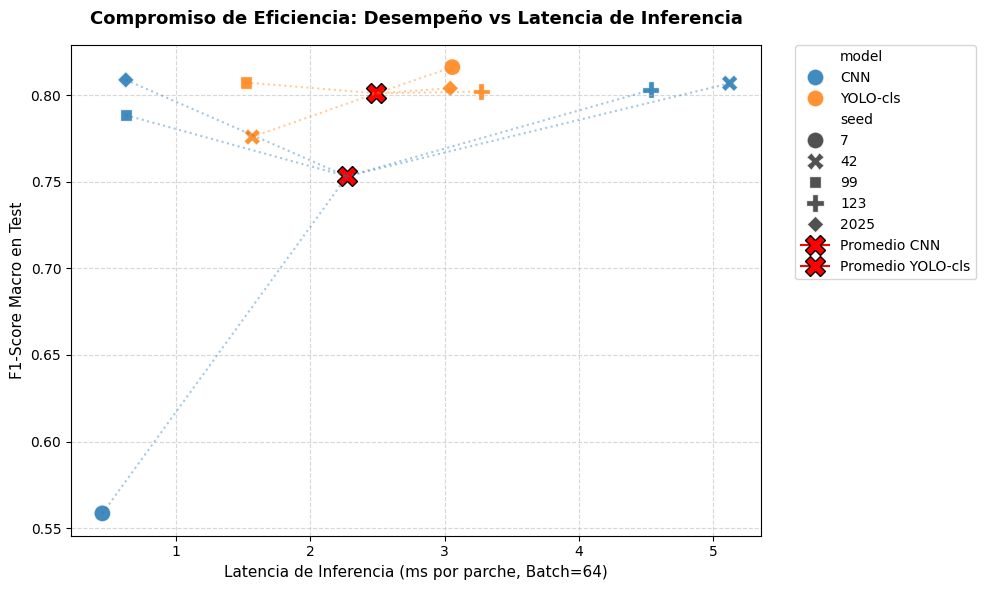


¡Gráfico generado con éxito y guardado en:
 -> /content/drive/MyDrive/cnn_yolo_idc_results/analisis_errores/desempeno_vs_latencia.png


In [2]:
# 12. Gráfico de Desempeño (F1-score Macro) vs Latencia de Inferencia (Soporte Local y Drive)
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Buscar el archivo de métricas de forma flexible (Local o Drive)
metrics_file_local = Path('/content/metrics_runs.csv')
metrics_file_drive = Path('/content/drive/MyDrive/cnn_yolo_idc_results/metrics_runs.csv')

# Determinar la ruta de lectura activa
if metrics_file_local.exists():
    metrics_file = metrics_file_local
    print("Usando archivo de métricas local: /content/metrics_runs.csv")
elif metrics_file_drive.exists():
    metrics_file = metrics_file_drive
    print("Usando archivo de métricas en Drive: /content/drive/MyDrive/cnn_yolo_idc_results/metrics_runs.csv")
else:
    metrics_file = None

# Ruta de salida para guardar el gráfico
grafico_output_dir = Path('/content/drive/MyDrive/cnn_yolo_idc_results/analisis_errores')
try:
    grafico_output_dir.mkdir(parents=True, exist_ok=True)
except Exception:
    # Si no está montado Drive, se guarda localmente en Colab
    grafico_output_dir = Path('/content/analisis_errores')
    grafico_output_dir.mkdir(parents=True, exist_ok=True)

if metrics_file is not None:
    df_metrics = pd.read_csv(metrics_file)

    # Crear la figura para el análisis de eficiencia académica
    plt.figure(figsize=(10, 6))

    # Paleta de colores distintivos para los modelos
    palette = {'CNN': '#1f77b4', 'YOLO-cls': '#ff7f0e'}

    # Graficar la dispersión de cada semilla individual para ver la estabilidad
    sns.scatterplot(
        data=df_metrics,
        x='latency_ms_per_patch_batch64',
        y='f1_macro',
        hue='model',
        style='seed',
        palette=palette,
        s=150,
        alpha=0.85
    )

    # Calcular y graficar el centroide (promedio) de cada modelo para mostrar la tendencia general
    for model_name in df_metrics['model'].unique():
        sub_df = df_metrics[df_metrics['model'] == model_name]
        mean_latency = sub_df['latency_ms_per_patch_batch64'].mean()
        mean_f1 = sub_df['f1_macro'].mean()

        plt.plot(
            mean_latency, mean_f1,
            marker='X', color='red', markersize=14,
            markeredgecolor='black', label=f'Promedio {model_name}'
        )

        # Añadir una línea sutil conectando los puntos de cada modelo con su promedio
        for _, row in sub_df.iterrows():
            plt.plot([row['latency_ms_per_patch_batch64'], mean_latency], [row['f1_macro'], mean_f1],
                     color=palette[model_name], linestyle=':', alpha=0.4)

    # Configuración de etiquetas y formato académico
    plt.title('Compromiso de Eficiencia: Desempeño vs Latencia de Inferencia', fontsize=13, fontweight='bold', pad=15)
    plt.xlabel('Latencia de Inferencia (ms por parche, Batch=64)', fontsize=11)
    plt.ylabel('F1-Score Macro en Test', fontsize=11)
    plt.grid(True, linestyle='--', alpha=0.5)

    # Ajustar leyendas
    plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left', borderaxespad=0.)
    plt.tight_layout()

    # Guardar gráfico en formato de alta resolución
    plot_path = grafico_output_dir / 'desempeno_vs_latencia.png'
    plt.savefig(plot_path, dpi=300, bbox_inches='tight')
    plt.show()

    print(f"\n¡Gráfico generado con éxito y guardado en:")
    print(f" -> {plot_path}")
else:
    print("ALERTA: No se encontró 'metrics_runs.csv' ni en /content/ ni en Google Drive.")
    print("Por favor, sube el archivo a la barra lateral de archivos de Colab (ruta: /content/metrics_runs.csv) y vuelve a ejecutar esta celda.")